# LightGBM: chẩn đoán (Thiện)

Notebook chỉ **đọc** các bảng do `python src/LightGBM/process/lightgbm_diag.py mekong 10` sinh ra trong `src/LightGBM/result/tables/` và vẽ lại; logic nằm ở `src/LightGBM/process/lightgbm_diag.py`.

Quy ước: seed chỉ đổi bagging; chạy nhiều seed để đo độ ổn định, không để chọn seed tốt nhất. Mọi số trong report phải trích từ các bảng này.

In [1]:
import pandas as pd
import sys

from floodbench.data.regions import repo_root

LGBM = repo_root() / "src" / "LightGBM"
sys.path.insert(0, str(LGBM / "process"))
from lightgbm_diag import gain_concentration

T = LGBM / "result" / "tables"
cfgs = pd.read_csv(T / "lightgbm_chosen_configs.csv")
imp = pd.read_csv(T / "lightgbm_feature_importance.csv")
seeds = pd.read_csv(T / "lightgbm_seed_summary.csv")
phase = pd.read_csv(T / "lightgbm_phase_by_season_h2.csv")
SEED0 = 0

## 1. Cấu hình được chọn ở từng fold và từng tầm (seed 0, đúng như benchmark)

Id cấu hình theo `LGBM_GRID` trong `models/ml.py`: 0 = (4, 200, 0,05), 1 = (4, 100, 0,05), 2 = (8, 200, 0,05), 3 = (4, 400, 0,03), 4 = (2, 300, 0,05), 5 = (8, 100, 0,10).

In [2]:
c0 = cfgs[cfgs["seed"] == SEED0]
for m, g in c0.groupby("model"):
    print(m)
    print(g.pivot(index="h", columns="test_season", values="cfg_index").to_string(), "\n")
print("Số lần chọn mỗi num_leaves (33 lần mỗi biến thể):")
print(c0.groupby(["model", "num_leaves"]).size().unstack(fill_value=0).to_string())

lgbm_anomaly
test_season  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020
h                                                                            
1               5     4     4     4     1     1     1     1     1     4     4
2               4     4     4     4     1     1     1     1     1     1     4
4               4     4     4     1     0     1     4     4     4     4     4 

lgbm_noclim
test_season  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020
h                                                                            
1               4     4     1     0     4     0     3     0     1     0     3
2               4     4     1     3     0     3     3     0     3     0     3
4               4     4     0     0     2     3     3     3     3     5     2 

lgbm_raw
test_season  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020
h                                                                            
1               4     4   

## 2. Độ quan trọng đặc trưng (gain) và SHAP trung bình tuyệt đối, seed 0

Trung bình qua 11 fold. Mô tả mô hình học gì, không phải quan hệ nhân quả.

In [3]:
i0 = imp[imp["seed"] == SEED0]
tab = i0.groupby(["model", "h", "feature"])[["gain_share", "mean_abs_shap"]].mean().round(3)
print(tab.to_string())

                           gain_share  mean_abs_shap
model        h feature                              
lgbm_anomaly 1 a_t              0.925       1121.153
               a_t1             0.037         86.349
               doy_target       0.038         99.763
             2 a_t              0.818        991.851
               a_t1             0.081        143.179
               doy_target       0.101        162.215
             4 a_t              0.743        889.658
               a_t1             0.121        143.100
               doy_target       0.136        194.349
lgbm_noclim  1 doy_target       0.089        706.380
               y_t              0.894       2481.369
               y_t1             0.009         98.919
               y_t2             0.008        119.498
             2 doy_target       0.292       1318.590
               y_t              0.675       2145.961
               y_t1             0.014        154.562
               y_t2             0.019        1

## 3. Độ ổn định theo seed (10 seed), so với AnomAR1

`rmse_sd_pct` là độ lệch chuẩn (ddof = 1) theo phần trăm của RMSE trung bình. `frac_seeds_better_than_base` là tỉ lệ seed có RMSE thấp hơn AnomAR1.

In [4]:
print(seeds.to_string(index=False))

       model  h  n_seeds  rmse_mean  rmse_sd  rmse_sd_pct  rmse_min  rmse_max  rmse_seed0  anom_ar1_rmse  mean_over_base  frac_seeds_better_than_base
lgbm_anomaly  1       10  1094.1520   4.4965       0.4110 1088.1380 1100.6036   1100.6036      1089.6288          1.0042                          0.1
lgbm_anomaly  2       10  1365.7401   8.8813       0.6503 1351.0389 1379.9279   1364.2064      1375.3818          0.9930                          0.9
lgbm_anomaly  4       10  1700.4546   9.6318       0.5664 1687.2872 1713.6358   1699.0222      1687.1045          1.0079                          0.0
 lgbm_noclim  1       10  1050.7923   7.6075       0.7240 1039.6664 1061.3431   1059.0031      1089.6288          0.9644                          1.0
 lgbm_noclim  2       10  1306.4215   5.9045       0.4520 1299.5593 1317.7202   1300.9813      1375.3818          0.9499                          1.0
 lgbm_noclim  4       10  1819.0457  20.7388       1.1401 1777.6950 1840.9166   1777.6950      1687.

## 4. Lợi thế theo từng mùa ở từng giai đoạn lũ (lgbm_raw so với anom_ar1, h = 2)

`ratio` < 1: LightGBM tốt hơn. `sse_gain` > 0: mức giảm tổng bình phương sai số.

In [5]:
for name in ("rising", "peak", "falling"):
    print(gain_concentration(phase, name))
print()
print(phase.pivot(index="season", columns="phase", values="ratio").round(2).to_string())

{'phase': 'rising', 'seasons': 11, 'seasons_better': 8, 'total_gain': 23115885.3081, 'top_k': 3, 'top_k_gain': 16190216.0765, 'top_k_share': 0.7003935112460007}
{'phase': 'peak', 'seasons': 11, 'seasons_better': 6, 'total_gain': -27000372.1867, 'top_k': 3, 'top_k_gain': 9221543.0977, 'top_k_share': nan}
{'phase': 'falling', 'seasons': 11, 'seasons_better': 7, 'total_gain': 65416685.7927, 'top_k': 3, 'top_k_gain': 48252976.5964, 'top_k_share': 0.7376249042837426}

phase   falling  peak  rising
season                       
2010       1.49  0.99    0.89
2011       0.99  1.39    1.32
2012       0.82  1.26    0.90
2013       1.63  1.62    0.79
2014       0.73  0.79    1.01
2015       0.61  0.94    1.17
2016       0.86  1.39    0.90
2017       1.21  0.99    0.77
2018       1.06  1.00    0.83
2019       0.53  0.91    0.90
2020       0.88  0.93    0.69


## 5. Permutation importance theo khối mùa

Sinh bởi `python src/LightGBM/process/lightgbm_diag.py extras mekong`. Mỗi mùa test là một khối; `delta_rmse_mean` là mức tăng RMSE (km²) khi đổi chỗ ngẫu nhiên đặc trưng hoặc nhóm; `folds_positive` là số mùa (trên 11) có mức tăng > 0. Gain và permutation có thể không cùng ý (xem `lgbm_anomaly`, `calendar`): không xếp hạng đặc trưng từ một thước đo.

In [6]:
perm = pd.read_csv(T / "lightgbm_permutation_summary.csv")
print(perm[perm["kind"] == "group"].round(0).to_string(index=False))
print()
print(perm[perm["kind"] == "single"].round(0).to_string(index=False))

       model  h        unit  kind  folds  folds_positive  delta_rmse_mean  delta_rmse_sd
    lgbm_raw  1       level group     11              11           1899.0          800.0
    lgbm_raw  1 climatology group     11              11            281.0          159.0
    lgbm_raw  1    calendar group     11              11            435.0          122.0
lgbm_anomaly  1     anomaly group     11              11            720.0          471.0
lgbm_anomaly  1    calendar group     11               4              9.0           48.0
 lgbm_noclim  1       level group     11              11           2414.0          960.0
 lgbm_noclim  1    calendar group     11              11            620.0          163.0
    lgbm_raw  2       level group     11              10           1068.0          630.0
    lgbm_raw  2 climatology group     11              11            701.0          242.0
    lgbm_raw  2    calendar group     11              11            576.0          192.0
lgbm_anomaly  2     a

## 6. Vì sao Random Forest cùng đặc trưng không có lợi thế khi nước rút? (h = 2)

Mô hình **cố định** (không chọn bằng validation), cùng đặc trưng `raw`, chỉ để mô tả. `bias_*` là sai số trung bình (dự báo trừ thực tế; dương là dự báo cao hơn). Một seed, 11 mùa test, pha nước rút chỉ có 88 dòng; mọi cơ chế là giả thuyết.

In [7]:
fixed = pd.read_csv(T / "lightgbm_vs_rf_fixed_configs_h2.csv")
print(fixed.round(0).to_string(index=False))
print()
cols = ["rmse_all", "rmse_rising", "rmse_peak", "rmse_falling", "bias_falling"]
print(fixed.groupby("family")[cols].agg(["min", "max"]).round(0).to_string())

                                           model               family  h  rmse_all  rmse_rising  bias_rising  rmse_peak  bias_peak  rmse_falling  bias_falling
    RF lưới 0: depth=4, leaf=5, max_features=1.0       RF (lưới nhóm)  2    1462.0        996.0        269.0     1569.0     -425.0        1784.0         663.0
    RF lưới 1: depth=8, leaf=5, max_features=1.0       RF (lưới nhóm)  2    1433.0        963.0        226.0     1574.0     -352.0        1734.0         599.0
 RF lưới 2: depth=None, leaf=5, max_features=1.0       RF (lưới nhóm)  2    1433.0        964.0        225.0     1575.0     -353.0        1732.0         597.0
RF lưới 3: depth=None, leaf=10, max_features=1.0       RF (lưới nhóm)  2    1512.0        948.0        211.0     1606.0     -517.0        1903.0         739.0
    RF lưới 4: depth=8, leaf=5, max_features=0.5       RF (lưới nhóm)  2    1389.0        988.0        299.0     1516.0     -438.0        1651.0         567.0
 RF lưới 5: depth=None, leaf=5, max_features=0



                     rmse_all         rmse_rising         rmse_peak         rmse_falling         bias_falling        
                          min     max         min     max       min     max          min     max          min     max
family                                                                                                               
LightGBM (lưới nhóm)   1256.0  1315.0      1007.0  1066.0    1490.0  1563.0       1248.0  1442.0        167.0   385.0
LightGBM (thêm, sâu)   1426.0  1438.0      1129.0  1132.0    1601.0  1669.0       1523.0  1607.0        520.0   579.0
RF (lưới nhóm)         1388.0  1512.0       948.0   996.0    1516.0  1606.0       1649.0  1903.0        567.0   739.0
RF (thêm, nông)        1558.0  1694.0       980.0  1045.0    1625.0  1650.0       1980.0  2233.0        880.0  1034.0


## 6b. Hai mùa tiêu biểu (2011 lũ lớn nhất, 2015 lũ thấp nhất)

Bảng RMSE theo mùa: `lightgbm_season_rmse.csv`; hình `season_examples.png` ở mục 7. Sinh bởi `python src/LightGBM/process/lightgbm_diag.py seasons mekong`.

In [8]:
seas = pd.read_csv(T / "lightgbm_season_rmse.csv")
print(seas[seas["season"].isin([2011, 2015])].round(2).to_string(index=False))

 season  h  rmse_model  rmse_base  ratio  peak_km2  peak_rank
   2011  1      999.12     885.91   1.13  13768.80          1
   2011  2     1470.24    1232.01   1.19  13768.80          1
   2011  4     1955.97    1248.00   1.57  13768.80          1
   2015  1      983.91    1233.01   0.80   8604.95         11
   2015  2     1244.36    1578.83   0.79   8604.95         11
   2015  4     2366.43    2248.36   1.05   8604.95         11

## 7. Hình (đã lưu ở `src/LightGBM/result/figures/`)

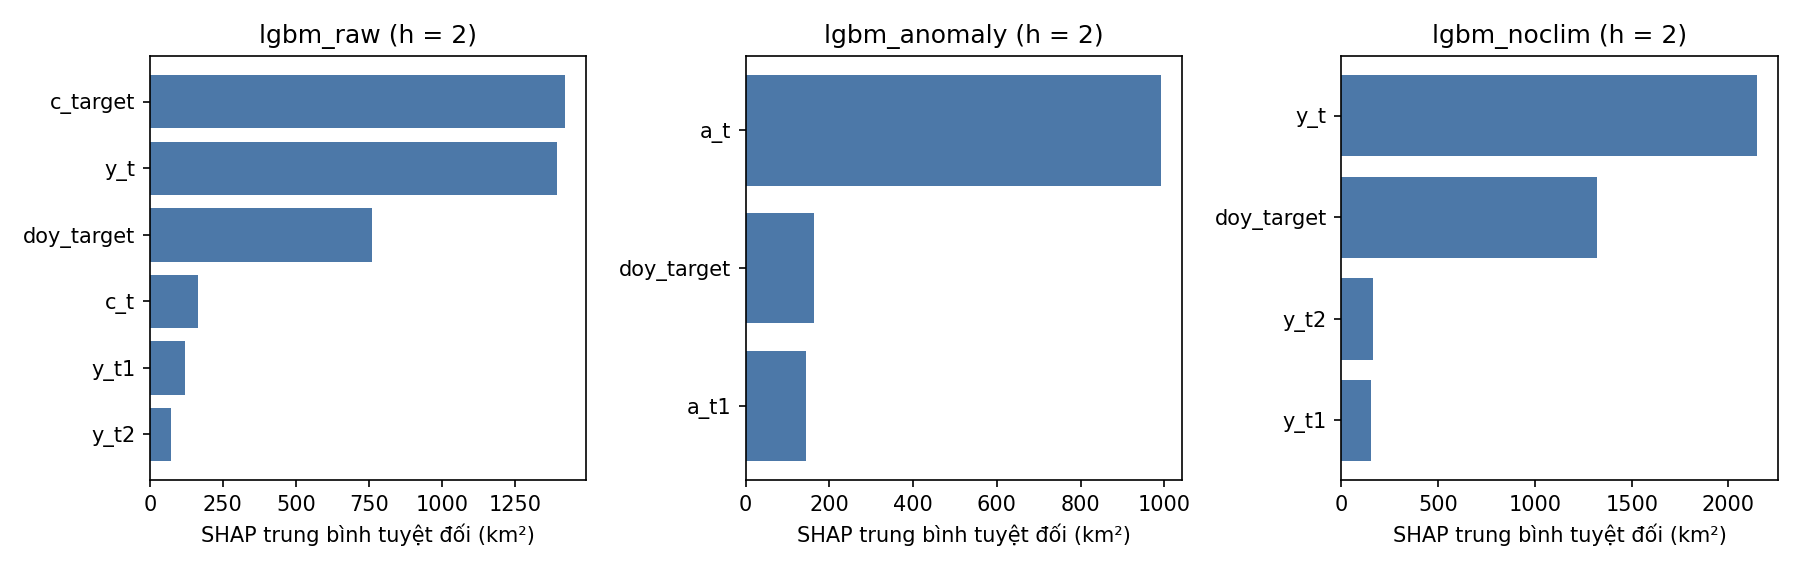

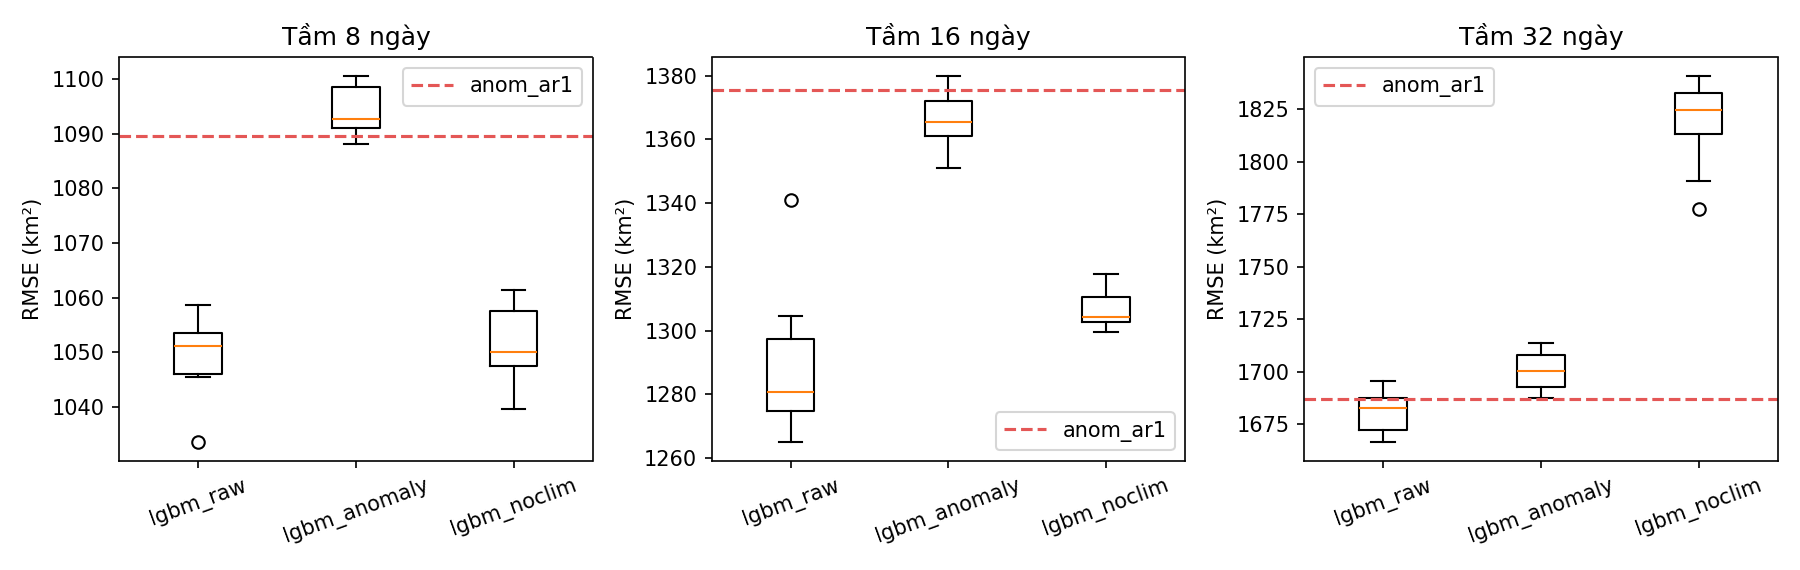

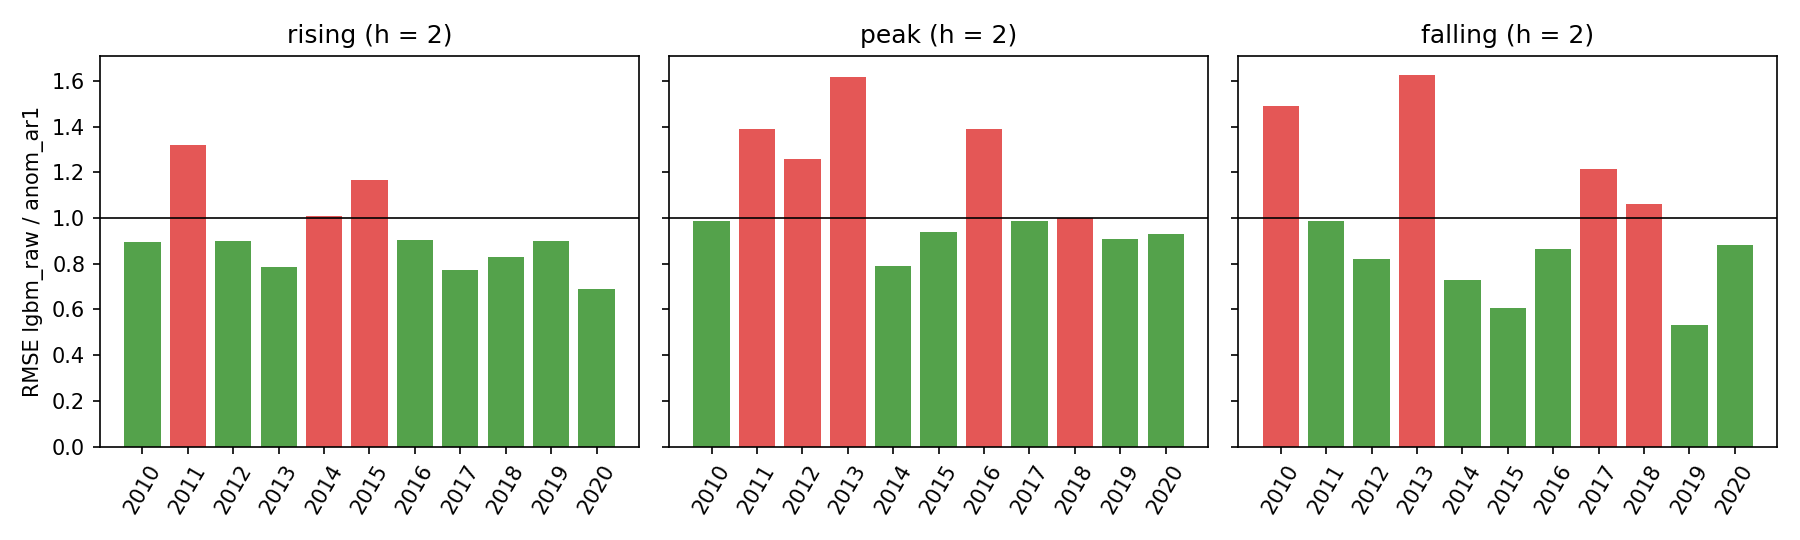

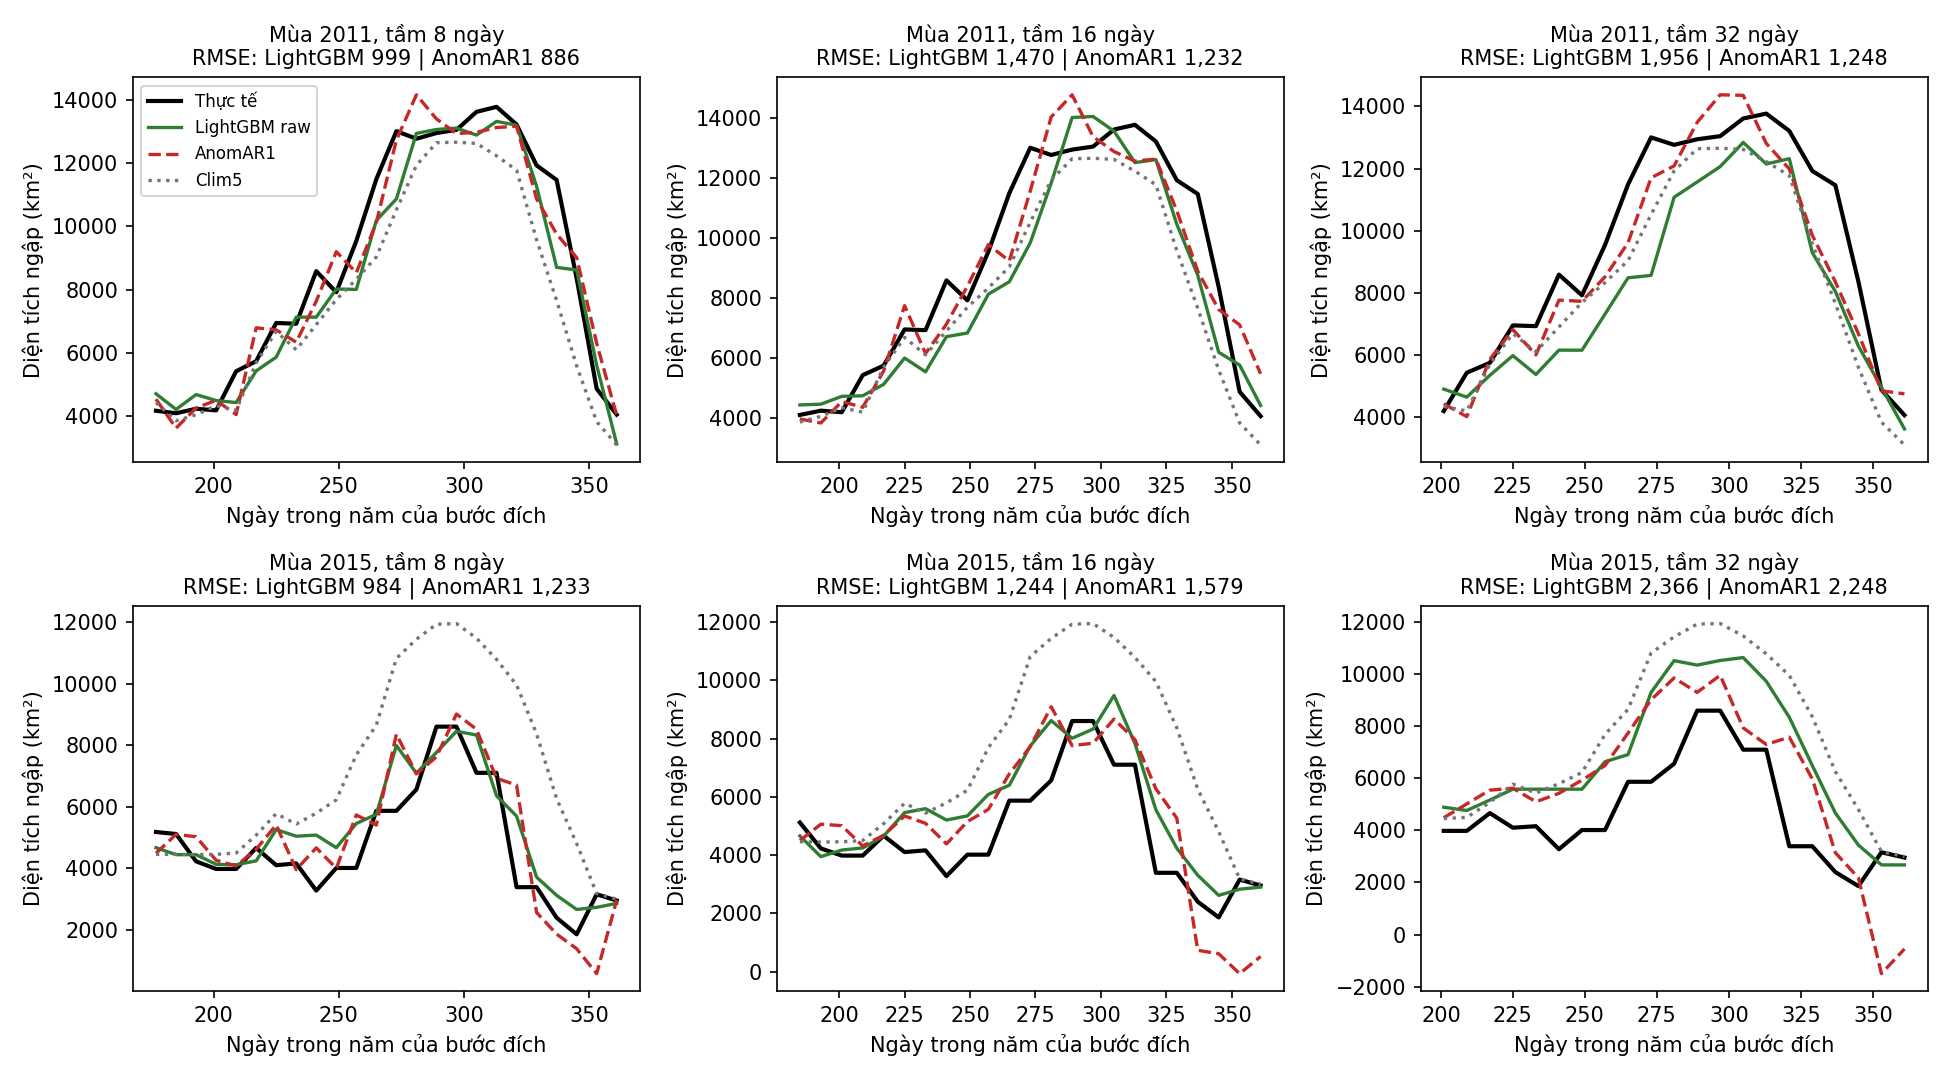

In [9]:
from IPython.display import Image, display
for f in ("shap_h2.png", "seed_rmse.png", "phase_ratio_by_season_h2.png", "season_examples.png"):
    display(Image(filename=str(LGBM / "result" / "figures" / f)))